# GameTheory-05c — Conditions KKT : la dualité lagrangienne en pratique

**Navigation** : [<< 05b](GameTheory-05b-Lean-Minimax-Lean.ipynb) | [Index](README.md) | [06 >>](GameTheory-06-EvolutionTrust-Python.ipynb)

Ce carnet prolonge le carnet [05](GameTheory-05-ZeroSum-Minimax-Python.ipynb) : là où le théorème minimax
résolvait les jeux à somme nulle par un programme linéaire, nous prenons du recul et étudions
**l'outil qui se cache derrière la dualité LP** : le lagrangien et les **conditions de Karush-Kuhn-Tucker (KKT)**.

> **Résultat central du carnet.** Sous une condition de régularité (qualification des contraintes),
> tout minimum local d'un problème contraint satisfait les quatre conditions KKT ; si le problème est
> convexe, ces conditions deviennent en outre **suffisantes** pour la minimalité globale, et sous la
> condition de Slater la dualité est **forte** (gap nul).

### Objectifs d'apprentissage

1. Construire le **lagrangien** et la **fonction duale** d'un problème contraint, et vérifier numériquement la **dualité faible**.
2. Énoncer les **quatre conditions KKT** et comprendre le rôle des **conditions de régularité** (qualification de Kuhn-Tucker, condition de Slater).
3. Résoudre l'équilibre d'un jeu à somme nulle par LP et **lire la stratégie de l'adversaire dans les variables duales** (marginales de `linprog`).
4. Résoudre une allocation convexe (utilités log) et interpréter $\lambda$ comme **prix d'ombre**.
5. Distinguer **conditions nécessaires** (non-convexe) et **nécessaires et suffisantes** (convexe), sur un contre-exemple explicite.

### Prérequis

- Carnet [05](GameTheory-05-ZeroSum-Minimax-Python.ipynb) : jeux à somme nulle, programme linéaire, théorème minimax.
- Bases de calcul différentiel : gradient, convexité.

**Durée estimée :** 45-60 minutes.

**Source primaire.** Les énoncés historiques et mathématiques de ce carnet sont ancrés dans les copies archivées suivantes (gisement `G:\Mon Drive\MyIA\IA\Bibliographie IA`) :

- Kuhn & Tucker (1951), *Nonlinear Programming*, Proceedings of the Second Berkeley Symposium, pp. 481-492 — rayon `GameTheory` : théorème 1 (nécessité sous qualification des contraintes), formulation en point de selle du lagrangien, lien explicite avec les jeux à somme nulle.
- Slater (1950), *Lagrange Multipliers Revisited*, Cowles Commission Discussion Paper, Math 403 — rayon `GameTheory` : origine de la condition d'intériorité dite « de Slater ».
- Boyd & Vandenberghe (2004), *Convex Optimization*, Cambridge University Press, §5.2 — rayon `Search` : énoncé moderne (dualité faible/forte, condition de Slater, raffinement affine).

In [1]:
%matplotlib inline
import numpy as np
from scipy.optimize import linprog, minimize
import sympy as sp
import matplotlib.pyplot as plt

print("Imports OK : numpy", np.__version__, "| scipy (linprog, minimize) | sympy", sp.__version__)

Imports OK : numpy 2.4.2 | scipy (linprog, minimize) | sympy 1.14.0


## 1. Pourquoi la dualité lagrangienne ?

Dans le carnet 05, l'équilibre d'un jeu à somme nulle tombait d'un programme linéaire, et la dualité
LP donnait la stratégie de l'adversaire. Kuhn et Tucker (1951) introduisent leur article exactement
par cette porte : le lagrangien d'un programme linéaire admet un **point de selle** qui, écrivent-ils,
*« provides a solution for a related zero sum two person game »* — le point de selle du lagrangien
**est** la paire de stratégies en équilibre.

La dualité lagrangienne généralise cette idée à **n'importe quelle** fonction objectif et **n'importe
quelles** contraintes différentiables. Le prix à payer : la solution n'est plus produite par un
simplexe, elle est **caractérisée** par des conditions d'optimalité — les conditions KKT — qui relient
le primal et le dual par des multiplicateurs.

### Le problème primal

Tout au long du carnet, on considère le problème

$$\min_{x \in \mathbb{R}^n} \ f_0(x) \quad \text{s.c.} \quad g_i(x) \le 0, \ i = 1, \dots, m.$$

(Les contraintes d'égalité $h_j(x) = 0$ s'ajoutent sans difficulté ; on les omet pour alléger.)

### 1.1 Le lagrangien et la fonction duale

Le **lagrangien** incorpore les contraintes dans l'objectif, pondérées par des multiplicateurs $\lambda_i \ge 0$ :

$$\mathcal{L}(x, \lambda) = f_0(x) + \sum_{i=1}^{m} \lambda_i \, g_i(x).$$

La **fonction duale** est la meilleure borne inférieure obtenue en minimisant sur $x$ :

$$\theta(\lambda) = \inf_x \ \mathcal{L}(x, \lambda).$$

Pour tout $\lambda \ge 0$, $\theta(\lambda)$ est une **borne inférieure** sur la valeur optimale $p^\star$ du
primal (dualité faible) — l'analyste continu du théorème de dualité faible que le lake Lean
[`assignment_lean`](assignment_lean/Assignment/Duality.lean) prouve formellement pour le problème
d'affectation (voir le carnet [Coalitions-04](Coalitions/Coalitions-04-Munkres-Affectation-Python.ipynb)).

**Exemple fil rouge.** Prenons $f_0(x) = (x-2)^2$ avec la contrainte $g(x) = x \le 0$. Le minimiseur
non contraint $x = 2$ est hors domaine ; l'optimum est $x^\star = 0$, $p^\star = 4$. Le calcul est fermé :

$$\theta(\lambda) = \min_x \left[ (x-2)^2 + \lambda x \right] = 2\lambda - \frac{\lambda^2}{4},$$

car le minimiseur intérieur du lagrangien est $x(\lambda) = 2 - \lambda/2$. Nous vérifions cette formule
**numériquement** (minimisation sur une grille), traçons $\theta$ face à $p^\star$, et contrôlons la dualité faible.

Forme fermee contre grille numerique : ecart max = 1.78e-15


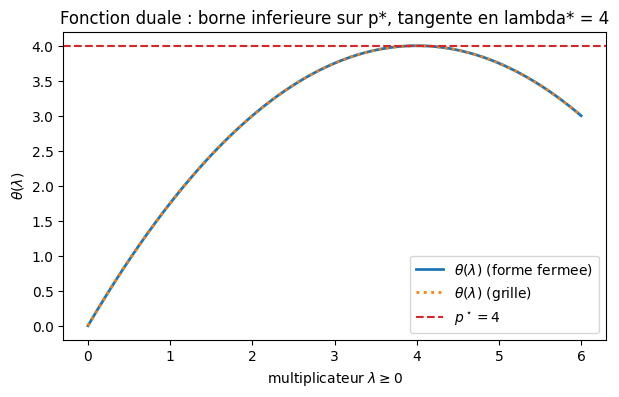

Dualite faible : 301 valeurs de lambda testees, 0 violation(s) de theta <= p*
Meilleure borne duale : max theta = 4.000000 en lambda = 4.00
Gap de dualite en lambda* = 4 : p* - theta(4) = 0.00e+00  (dualite FORTE)


In [2]:
# Exemple fil rouge :  min (x-2)^2   s.c.   g(x) = x <= 0.
# Optimum primal : x* = 0 (la contrainte est saturee), p* = f(0) = 4.
p_star = 4.0

def theta_ferme(lam):
    """Fonction duale en forme fermee : theta(lam) = 2*lam - lam^2/4."""
    return 2.0 * lam - lam**2 / 4.0

xs = np.linspace(-3.0, 5.0, 4001)        # grille de verification numerique
lambdas = np.linspace(0.0, 6.0, 301)     # multiplicateurs testes

th_ferme = theta_ferme(lambdas)
th_num = np.array([np.min((xs - 2.0) ** 2 + lam * xs) for lam in lambdas])
print(f"Forme fermee contre grille numerique : ecart max = {np.max(np.abs(th_ferme - th_num)):.2e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lambdas, th_ferme, lw=2, label=r"$\theta(\lambda)$ (forme fermee)")
ax.plot(lambdas, th_num, ":", lw=2, label=r"$\theta(\lambda)$ (grille)")
ax.axhline(p_star, color="tab:red", ls="--", label=r"$p^\star = 4$")
ax.set_xlabel(r"multiplicateur $\lambda \geq 0$")
ax.set_ylabel(r"$\theta(\lambda)$")
ax.set_title("Fonction duale : borne inferieure sur p*, tangente en lambda* = 4")
ax.legend()
plt.show()

violations = int(np.sum(th_ferme > p_star + 1e-12))
i_best = int(np.argmax(th_ferme))
print(f"Dualite faible : {len(lambdas)} valeurs de lambda testees, {violations} violation(s) de theta <= p*")
print(f"Meilleure borne duale : max theta = {th_ferme[i_best]:.6f} en lambda = {lambdas[i_best]:.2f}")
print(f"Gap de dualite en lambda* = 4 : p* - theta(4) = {p_star - theta_ferme(4.0):.2e}  (dualite FORTE)")

### 1.2 Lecture : une borne certifiée, et un certificat qui se lit dans la courbe

La courbe $\theta(\lambda)$ ne dépasse jamais $p^\star$ : chaque $\lambda \ge 0$ fabrique une borne
inférieure **certifiée** sans résoudre le primal. Le sommet est atteint en $\lambda^\star = 4$, avec
$\theta(\lambda^\star) = p^\star$ : la dualité est **forte**, et le multiplicateur optimal est
**strictement positif** — signature d'une contrainte **saturée** à l'optimum ($g(x^\star) = 0$, donc
l'écart complémentaire $\lambda^\star g(x^\star) = 0$ tient par les deux branches à la fois).

C'est exactement la structure que le lake Lean `assignment_lean` prouve formellement pour le problème
d'affectation — extrait de [`Assignment/Duality.lean`](assignment_lean/Assignment/Duality.lean) :

```lean
def DualFeasible : Prop := ∀ i j, u i + v j ≤ C i j

theorem weak_duality (h : DualFeasible C u v) (σ : Equiv.Perm (Fin n)) :
    dualValue u v ≤ value C σ := by ...
```

toute solution duale réalisable ($u_i + v_j \le C_{ij}$ partout) borne inférieurement la valeur de
n'importe quelle affectation $\sigma$. Dualité faible : une propriété **toujours vraie**, prouvable en
Lean 4 comme vérifiable en quelques lignes de NumPy.

## 2. Les quatre conditions KKT

Le lagrangien ne sert pas qu'à borner : à l'optimum, le couple $(x^\star, \lambda^\star)$ satisfait un
système de quatre conditions — les **conditions de Karush-Kuhn-Tucker** :

| # | Condition | Écriture | Lecture |
|---|-----------|----------|---------|
| 1 | **Stationnarité** | $\nabla f_0(x^\star) + \sum_i \lambda_i^\star \nabla g_i(x^\star) = 0$ | le gradient de l'objectif se compense dans les directions des contraintes |
| 2 | **Faisabilité primale** | $g_i(x^\star) \le 0$ | $x^\star$ est admissible |
| 3 | **Faisabilité duale** | $\lambda_i^\star \ge 0$ | les multiplicateurs pointent dans le bon sens |
| 4 | **Écart complémentaire** | $\lambda_i^\star \, g_i(x^\star) = 0$ | chaque multiplicateur est nul **ou** sa contrainte est saturée — jamais les deux inactifs |

### Nécessaires quand ? Suffisantes quand ?

La subtilité — c'est tout l'objet des articles fondateurs — tient en deux colonnes :

- **Nécessité.** Kuhn et Tucker (1951, théorème 1) démontrent que si $x^\star$ résout le problème et si
  les contraintes satisfont leur *constraint qualification* — un arc différentiable doit pouvoir
  quitter chaque point frontière dans les directions admissibles ; leur contre-exemple en deux
  dimensions, la courbe $(1-x_1)^3 \ge x_2$, possède un point frontière singulier $(1, 0)$ où la
  stationnarité peut échouer pour tout choix de multiplicateurs — alors il existe des $\lambda^\star \ge 0$
  tels que stationnarité et écart complémentaire aient lieu (la preuve passe par le lemme de Farkas).
- **Suffisance.** Si $f_0$ et les $g_i$ sont **convexes**, tout point satisfaisant les quatre conditions
  est un **minimiseur global** — la convexité transforme le certificat local en garantie globale.
- **Dualité forte.** Pour un problème convexe, la condition de **Slater** — il existe un point
  **strictement réalisable** : $g_i(x) < 0$ pour toute contrainte $g_i$ non affine (Boyd & Vandenberghe
  2004, §5.2.3, éq. 5.26) — garantit $d^\star = p^\star$ **et** l'atteinte de l'optimum dual. Raffinement :
  les contraintes affines n'ont pas besoin d'être strictes.

La section 5 montrera sur un contre-exemple que sans convexité, « satisfait KKT » ne dit plus rien sur
la valeur : un point KKT peut être le minimiseur global — ou rien du tout.

In [3]:
def kkt_report(grad_f, g_list, jac_g_list, x_star, lam, tol=1e-6, nom="point"):
    """Verifie les quatre conditions KKT en x_star pour le probleme  min f  s.c.  g_i <= 0.

    grad_f     : gradient de l'objectif (fonction numpy -> vecteur).
    g_list     : liste des contraintes g_i (chacune doit etre <= 0).
    jac_g_list : liste des gradients des g_i.
    lam        : multiplicateurs associes aux contraintes.
    Retourne un dict de verdicts ; ne leve jamais d'erreur (c'est un rapport, pas une garde).
    """
    x_star = np.asarray(x_star, dtype=float)
    lam = np.asarray(lam, dtype=float)
    residu_stat = float(np.linalg.norm(
        np.asarray(grad_f(x_star))
        + sum(lam[i] * np.asarray(jac_g_list[i](x_star)) for i in range(len(g_list)))))
    g_vals = np.array([g(x_star) for g in g_list], dtype=float)
    rapport = {
        "stationarite": residu_stat,
        "faisabilite_primale": float((-g_vals).min()),   # > -tol : toutes les g_i <= 0
        "faisabilite_duale": float(lam.min()),           # >= -tol : tous les lambda_i >= 0
        "complementarite": float(np.max(np.abs(lam * g_vals))),
    }
    verdicts = {
        "stationarite": rapport["stationarite"] < tol,
        "faisabilite_primale": rapport["faisabilite_primale"] > -tol,
        "faisabilite_duale": rapport["faisabilite_duale"] > -tol,
        "complementarite": rapport["complementarite"] < tol,
    }
    print(f"Rapport KKT ({nom}) :")
    for cle, ok in verdicts.items():
        print(f"  {cle:22s} residu = {rapport[cle]:+.3e}  ->  {'OK' if ok else 'ECHEC'}")
    return verdicts

# Demonstration sur le fil rouge : x* = 0, lambda* = 4, g(x) = x <= 0.
_ = kkt_report(
    grad_f=lambda x: np.array([2.0 * (x[0] - 2.0)]),
    g_list=[lambda x: x[0]],
    jac_g_list=[lambda x: np.array([1.0])],
    x_star=np.array([0.0]),
    lam=np.array([4.0]),
    nom="fil rouge : x* = 0, lambda* = 4",
)

Rapport KKT (fil rouge : x* = 0, lambda* = 4) :


  stationarite           residu = +0.000e+00  ->  OK
  faisabilite_primale    residu = -0.000e+00  ->  OK
  faisabilite_duale      residu = +4.000e+00  ->  OK
  complementarite        residu = +0.000e+00  ->  OK


## 3. Application 1 — l'équilibre d'un jeu à somme nulle, relu par les marginales

Reprenons la formulation du carnet [05](GameTheory-05-ZeroSum-Minimax-Python.ipynb) : le joueur ligne
choisit une mixture $p$ qui maximise sa garantie $v$ contre toutes les colonnes :

$$\max_{p, v} \ v \quad \text{s.c.} \quad A^\top p \ge v \, \mathbb{1}, \quad \mathbb{1}^\top p = 1, \quad p \ge 0,$$

un programme linéaire que `scipy.optimize.linprog` résout (sous forme de minimisation : $\min\, -v$).
La question que seule la dualité permet de poser : **que sont les variables duales ?**

Réponse : le dual de ce LP est **exactement** le LP du joueur colonne — c'est la lecture
game-théorique du point de selle de Kuhn et Tucker. En pratique, `linprog` rend ces multiplicateurs
dans `res.ineqlin.marginals` : ce sont les sensibilités de la valeur du jeu à un relâchement des
contraintes de colonne, et leur renormalisation **est la stratégie optimale de l'adversaire**.

**Jeu support.** Un pierre-feuille-ciseaux déformé : un seul coefficient change, le gain de Ciseaux
contre Feuille passe de $1$ à $1{,}5$. L'équilibre n'est plus uniforme — la déformation avantagé la
ligne, et l'excédent de valeur se calcule à la main : $v^\star = 1/21 > 0$, $p^\star = (8/21,\ 1/3,\ 2/7)$.
Nous vérifions ces valeurs, reconstruisons $q^\star$ depuis les marginales, et contrôlons l'écart
complémentaire colonne par colonne.

In [4]:
# Application 1 : equilibre d'un jeu a somme nulle par LP, duaux = strategie adverse.
# Pierre-feuille-ciseaux deforme : seul A[2][1] passe de 1 a 1.5.
A = np.array([[0.0, -1.0, 1.0],
              [1.0, 0.0, -1.0],
              [-1.0, 1.5, 0.0]])
m, n = A.shape

# LP du joueur ligne (maximiser la valeur v), variables z = (p_1, p_2, p_3, v) :
#   min  -v   s.c.  v - (A^T p)_j <= 0 pour chaque colonne j ;  somme(p) = 1 ;  p >= 0, v libre.
c = np.array([0.0, 0.0, 0.0, -1.0])
A_ub = np.hstack([-A.T, np.ones((n, 1))])
b_ub = np.zeros(n)
A_eq = np.array([[1.0, 1.0, 1.0, 0.0]])
b_eq = np.array([1.0])
bounds = [(0.0, None)] * m + [(None, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
p_star = res.x[:m]
v_star = res.x[m]
print("Statut LP :", res.message)
print(f"Strategie du joueur ligne p* = {np.round(p_star, 6)}   (valeur v* = {v_star:.6f})")
print(f"Attendu a la main          : p* = (8/21, 7/21, 6/21) = ({8/21:.6f}, {7/21:.6f}, {6/21:.6f}), v* = {1/21:.6f}")

# Marginales des contraintes d'inegalite : sensibilite de l'objectif a b_ub.
marg = res.ineqlin.marginals
print(f"\nMarginales (brutes) : {np.round(marg, 6)}")
lam = -marg                        # convention : duaux <= 0 pour un probleme de minimisation
q_star = lam / lam.sum()
print(f"Strategie adverse reconstruite depuis les marginales : q* = {np.round(q_star, 6)}")

# Verification 1 : q* garantit au plus v* contre toute ligne pure (definition de l'equilibre).
garanties_ligne = A @ q_star
print(f"\nGains de chaque ligne pure contre q* : A q* = {np.round(garanties_ligne, 6)}")
print(f"max_i (A q*)_i = {garanties_ligne.max():.6f}  vs  v* = {v_star:.6f}   (doivent coincider)")

# Verification 2 : ecarts complementaires lambda_j * (v* - (A^T p*)_j) = 0, colonne par colonne.
slacks = v_star - A.T @ p_star
print("\nEcart complementaire par colonne (lambda_j, slack_j, produit) :")
for j in range(n):
    print(f"  colonne {j} : lambda = {lam[j]:+.6f}, slack = {slacks[j]:+.2e}, produit = {lam[j]*slacks[j]:+.2e}")

Statut LP : Optimization terminated successfully. (HiGHS Status 7: Optimal)
Strategie du joueur ligne p* = [0.380952 0.333333 0.285714]   (valeur v* = 0.047619)
Attendu a la main          : p* = (8/21, 7/21, 6/21) = (0.380952, 0.333333, 0.285714), v* = 0.047619

Marginales (brutes) : [-0.380952 -0.285714 -0.333333]
Strategie adverse reconstruite depuis les marginales : q* = [0.380952 0.285714 0.333333]

Gains de chaque ligne pure contre q* : A q* = [0.047619 0.047619 0.047619]
max_i (A q*)_i = 0.047619  vs  v* = 0.047619   (doivent coincider)

Ecart complementaire par colonne (lambda_j, slack_j, produit) :
  colonne 0 : lambda = +0.380952, slack = +0.00e+00, produit = +0.00e+00
  colonne 1 : lambda = +0.285714, slack = +0.00e+00, produit = +0.00e+00
  colonne 2 : lambda = +0.333333, slack = +0.00e+00, produit = +0.00e+00


### 3.1 Lecture du résultat

- La valeur $v^\star = 1/21 \approx 0{,}048$ confirme l'avantage ligne : la mixture $p^\star$ dévie de
  l'uniforme au profit de Pierre ($8/21$) au détriment de Ciseaux ($2/7$).
- Les **marginales**, changées de signe et renormalisées, redonnent la stratégie $q^\star$ du joueur
colonne : le dual du LP de la ligne est le LP de la colonne. C'est le point de selle du lagrangien —
  l'objet que Kuhn et Tucker identifiaient d'emblée à une paire de stratégies d'un jeu à somme nulle.
- L'**écart complémentaire** se lit comme une condition de support : $\lambda_j > 0$ force la colonne
  $j$ à être **exactement** à la garantie ($(A^\top p^\star)_j = v^\star$) — les colonnes « jouées » par
  l'adversaire sont celles contre lesquelles la mixture de la ligne ne peut rien gagner de plus.

En LP, tout cela est automatique. L'intérêt des conditions KKT est de survivre au **non-linéaire** :
  la section suivante résout un problème où il n'y a plus de simplexe — mais toujours un lagrangien.

## 4. Application 2 — allocation convexe d'un budget, et prix d'ombre

Trois projets, utilités logarithmiques $a_i \log(1 + x_i)$, budget $B$ :

$$\max_{x \ge 0} \ \sum_{i} a_i \log(1 + x_i) \quad \text{s.c.} \quad \sum_i x_i \le B,
\qquad a = (3,\ 1,\ 0{,}5), \quad B = 4.$$

Le problème est **strictement concave** (donc son miroir en $-f$, convexe) et la contrainte de budget
est **affine** : Slater est triviale — tout $x > 0$ de somme $< B$ est strictement réalisable — donc la
dualité est forte et les conditions KKT sont **nécessaires et suffisantes**. La stationnarité intérieure
donne la structure **water-filling** :

$$\frac{a_i}{1 + x_i} = \lambda \quad \Longleftrightarrow \quad x_i = \max\!\left(0, \ \frac{a_i}{\lambda} - 1\right),$$

où $\lambda$ s'ajuste pour saturer le budget. Nous résolvons par SLSQP **et** par la forme fermée
(bisection sur $\lambda$), puis vérifions les quatre conditions KKT — y compris le multiplicateur de la
contrainte $x_3 \ge 0$, car avec ces données le projet 3 est « sec » : $a_3/\lambda - 1 < 0$ et
$x_3^\star = 0$.

In [5]:
# Application 2 : allocation convexe, SLSQP contre water-filling, prix d'ombre, rapport KKT complet.
a = np.array([3.0, 1.0, 0.5])
B = 4.0

def utilite(x):
    return float(np.sum(a * np.log1p(x)))

# --- Resolution numerique (SLSQP) ---
res = minimize(lambda x: -utilite(x), x0=np.full(3, B / 3.0),
               bounds=[(0.0, None)] * 3,
               constraints=[{"type": "ineq", "fun": lambda x: B - np.sum(x)}],
               method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
x_num = res.x
print("SLSQP          : x =", np.round(x_num, 8), "| utilite =", f"{utilite(x_num):.8f}")

# --- Forme fermee : water-filling par bisection sur lambda (prix d'ombre) ---
def water_filling(a_vec, budget):
    """Resout l'allocation log : x_i = max(0, a_i/lambda - 1), somme = budget, par bisection."""
    lo, hi = 1e-9, max(a_vec) / 1e-9
    for _ in range(200):
        lam = (lo + hi) / 2.0
        if np.sum(np.maximum(0.0, a_vec / lam - 1.0)) > budget:
            lo = lam
        else:
            hi = lam
    lam = (lo + hi) / 2.0
    return np.maximum(0.0, a_vec / lam - 1.0), lam

x_eau, lam_eau = water_filling(a, B)
print(f"Water-filling  : x = {np.round(x_eau, 8)}  |  lambda = {lam_eau:.8f}  (2/3 attendu)")
print(f"Ecart SLSQP vs water-filling : {np.max(np.abs(x_num - x_eau)):.2e}")

# Projet 3 sec : la contrainte x_3 >= 0 est active, son multiplicateur prend le relai
# (stationarite en x_3 = 0 :  -a_3 + lambda - mu_3 = 0  =>  mu_3 = lambda - a_3 = 1/6).
mu3 = lam_eau - a[2]

# --- Prix d'ombre par differences finies : dU/dB ~ lambda ---
eps = 1e-4
x_eps, _ = water_filling(a, B + eps)
prix_ombre_fd = (utilite(x_eps) - utilite(x_eau)) / eps
print(f"\nPrix d'ombre : differences finies dU/dB = {prix_ombre_fd:.6f}  vs  lambda = {lam_eau:.6f}")

# --- Rapport KKT complet : budget + positivite de chaque x_i ---
_ = kkt_report(
    grad_f=lambda x: -a / (1.0 + x),
    g_list=[lambda x: np.sum(x) - B, lambda x: -x[0], lambda x: -x[1], lambda x: -x[2]],
    jac_g_list=[
        lambda x: np.ones(3),
        lambda x: -np.eye(3)[0], lambda x: -np.eye(3)[1], lambda x: -np.eye(3)[2],
    ],
    x_star=x_eau,
    lam=np.array([lam_eau, 0.0, 0.0, mu3]),
    nom="allocation : x = (3.5, 0.5, 0), lambda_budget = 2/3, mu_3 = 1/6",
)

SLSQP          : x = [3.49999999 0.50000001 0.        ] | utilite = 4.91769730
Water-filling  : x = [3.5 0.5 0. ]  |  lambda = 0.66666667  (2/3 attendu)
Ecart SLSQP vs water-filling : 1.37e-08

Prix d'ombre : differences finies dU/dB = 0.666661  vs  lambda = 0.666667
Rapport KKT (allocation : x = (3.5, 0.5, 0), lambda_budget = 2/3, mu_3 = 1/6) :
  stationarite           residu = +0.000e+00  ->  OK
  faisabilite_primale    residu = -1.776e-15  ->  OK
  faisabilite_duale      residu = +0.000e+00  ->  OK
  complementarite        residu = +1.184e-15  ->  OK


### 4.1 Lecture du résultat

- SLSQP et water-filling coïncident à $1{,}4 \times 10^{-8}$ près — l'écart imprimé ci-dessus, de l'ordre de la tolérance de convergence du solveur : $x^\star = (3{,}5,\ 0{,}5,\ 0)$,
  $\lambda^\star = 2/3$. Le rapport KKT passe **avec** le multiplicateur $\mu_3 = 1/6$ de la contrainte
de positivité — à cet optimum, **deux** contraintes sont actives : le budget **et** le bord $x_3 = 0$.
- Le **prix d'ombre** $\lambda = 2/3$ est un prix **marginal** : la dérivée $\mathrm{d}U^\star/\mathrm{d}B$
  au budget $B = 4$, que la différence finie à petit pas ci-dessus retrouve ($0{,}666661$). Une unité
  **entière** de budget supplémentaire vaut moins — par concavité, $U^\star(5) - U^\star(4) =
  4\ln(7/6) \approx 0{,}617 < 2/3$. C'est la lecture économique du multiplicateur — la même quantité
  qui, côté primal, règle le partage entre projets.
- Gap nul, dualité forte, optimum dual atteint : tout ce que la condition de Slater garantit pour un
  problème convexe, vérifié chiffre à l'appui.

## 5. Convexe ou non : le même système, deux statuts

Pour un problème **convexe**, les quatre conditions KKT forment un **certificat de minimalité
globale** : qui vérifie le système n'a même pas besoin de connaître les autres candidats. Retirez la
convexité, et le même système ne certifie plus rien — chaque condition est locale, la courbure peut trahir.

Deux problèmes sur la même boîte $|x| \le 1$ :

$$\text{(convexe)} \quad \min\, x^2 \qquad\qquad \text{(non convexe)} \quad \min\, x^3.$$

Pour $x^3$, trois candidats se présentent : les deux bords $\pm 1$, et le point intérieur $x = 0$ où
$f'(0) = 0$. La faisabilité duale **rejette** $x = +1$ (son multiplicateur serait négatif) ; restent
$x = -1$ (bord gauche, $\lambda_2 = 3$) et $x = 0$ (multiplicateurs nuls) — et **tous deux satisfont les
quatre conditions**. Pourtant $f(-1) = -1 < f(0) = 0$ : le point $x = 0$ n'est même pas un minimum local,
puisque $f(-0{,}5) = -0{,}125 < 0$. Nécessaires, pas suffisantes.

In [6]:
# Convexite : le role decisif. Deux problemes sur la meme boite |x| <= 1.
g_box = [lambda x: x[0] - 1.0, lambda x: -x[0] - 1.0]
jac_box = [lambda x: np.array([1.0]), lambda x: np.array([-1.0])]

# --- Cas convexe : min x^2. Unique point KKT x = 0, minimum global. ---
print("Cas convexe : min x^2 s.c. |x| <= 1")
_ = kkt_report(grad_f=lambda x: np.array([2.0 * x[0]]),
               g_list=g_box, jac_g_list=jac_box,
               x_star=np.array([0.0]), lam=np.array([0.0, 0.0]), nom="x = 0")
grille = np.linspace(-1.0, 1.0, 20001)
print(f"Balayage : argmin grille = {grille[np.argmin(grille**2)]:+.4f}, "
      f"f(min) = {np.min(grille**2):.6f} = f(0)  ->  minimum GLOBAL\n")

# --- Cas non convexe : min x^3. Trois candidats stationnaires sur la boite. ---
# Stationnarite : 3x^2 + lambda_1 - lambda_2 = 0.
print("Cas non convexe : min x^3 s.c. |x| <= 1")
candidats = {
    "x = -1 (bord gauche)": (np.array([-1.0]), np.array([0.0, 3.0])),
    "x = 0  (interieur)":   (np.array([0.0]),  np.array([0.0, 0.0])),
    "x = +1 (bord droit)":  (np.array([1.0]),  np.array([-3.0, 0.0])),
}
for nom, (x_c, lam_c) in candidats.items():
    v = kkt_report(grad_f=lambda x: np.array([3.0 * x[0] ** 2]),
                   g_list=g_box, jac_g_list=jac_box,
                   x_star=x_c, lam=lam_c, nom=nom)
    verdict = "point KKT" if all(v.values()) else "rejete (faisabilite duale)"
    fv = float(x_c[0]) ** 3
    print(f"  f({x_c[0]:+.0f}) = {fv:+.2f}  ->  {verdict}\n")
print("Conclusion : x = 0 satisfait toutes les conditions KKT, mais f(-1) = -1 < f(0) = 0.")
print("En non-convexe, KKT est NECESSAIRE (sous regularite) mais PAS suffisante.")

Cas convexe : min x^2 s.c. |x| <= 1
Rapport KKT (x = 0) :
  stationarite           residu = +0.000e+00  ->  OK
  faisabilite_primale    residu = +1.000e+00  ->  OK
  faisabilite_duale      residu = +0.000e+00  ->  OK
  complementarite        residu = +0.000e+00  ->  OK
Balayage : argmin grille = +0.0000, f(min) = 0.000000 = f(0)  ->  minimum GLOBAL

Cas non convexe : min x^3 s.c. |x| <= 1
Rapport KKT (x = -1 (bord gauche)) :
  stationarite           residu = +0.000e+00  ->  OK
  faisabilite_primale    residu = -0.000e+00  ->  OK
  faisabilite_duale      residu = +0.000e+00  ->  OK
  complementarite        residu = +0.000e+00  ->  OK
  f(-1) = -1.00  ->  point KKT

Rapport KKT (x = 0  (interieur)) :
  stationarite           residu = +0.000e+00  ->  OK
  faisabilite_primale    residu = +1.000e+00  ->  OK
  faisabilite_duale      residu = +0.000e+00  ->  OK
  complementarite        residu = +0.000e+00  ->  OK
  f(+0) = +0.00  ->  point KKT

Rapport KKT (x = +1 (bord droit)) :
  stationari

### 5.1 Lecture du résultat

| Problème | Points KKT | Minimiseur global | Statut des conditions |
|---|---|---|---|
| $\min x^2$ (convexe) | $x = 0$ seul | $x = 0$ | nécessaires **et suffisantes** |
| $\min x^3$ (non convexe) | $x = -1$ et $x = 0$ | $x = -1$ | nécessaires seulement |

La colonne « points KKT » est le nœud : en non-convexe, **vérifier KKT ne choisit pas** entre les
candidats. C'est exactement ce que la convexité apporte : elle force $f_0$ à rester au-dessus de son
plan tangent lagrangien, et le certificat local devient global.

Boucle bouclée avec la section 1 : sous la condition de Slater (problème convexe), il existe un
$\lambda^\star$ qui réalise le maximum dual — le couple $(x^\star, \lambda^\star)$ est un **point de
selle** du lagrangien, la notation sous laquelle Kuhn et Tucker (1951) ont posé le problème, et l'objet
qu'ils identifiaient à l'équilibre d'un jeu à somme nulle.

## 6. Exercices

### Exercice 1 — Matching pennies, côté colonne

Reprenez le LP de la section 3 **pour le joueur colonne** sur la matrice de matching pennies
$A = \begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}$ : minimiser la valeur que la ligne peut garantir,
reconstruire la stratégie de la ligne depuis les marginales, et vérifier l'écart complémentaire.
Le jeu est équitable : la valeur attendue est $v^\star = 0$ et l'équilibre uniforme.

In [7]:
# Exercice 1 -- Matching pennies par LP, cote joueur colonne.
A_mp = np.array([[1.0, -1.0], [-1.0, 1.0]])

def equilibre_matching_pennies():
    """Resout le LP du joueur COLONNE sur A_mp et reconstruit la reponse de la ligne.

    Etapes :
      1. Ecrire le LP de minimisation de la valeur pour Col (miroir de celui de Row en section 3).
      2. Resoudre avec linprog(method="highs").
      3. Reconstruire la strategie de Row depuis les marginales.
      4. Verifier l'ecart complementaire ligne par ligne.
    Retour attendu : (q_star, v_star) avec v_star = 0 et q_star = (1/2, 1/2).
    """
    # TODO etudiant : votre code ici
    # Indice : le probleme est symetrique, la valeur attendue est 0 (jeu equitable).
    # Etape 1 : formuler  min v  s.c.  (A q)_i <= v pour chaque ligne i, somme(q) = 1, q >= 0.
    print("Exercice a completer")
    return None

resultat_mp = equilibre_matching_pennies()

Exercice a completer


### Exercice 2 — Water-filling à quatre projets, cellule sèche à identifier

Avec $a = (4,\ 3,\ 2,\ 1)$ et $B = 5$ : déterminez quels projets sont actifs à l'optimum, dérivez
$\lambda^\star$ sur les **seuls projets actifs**, donnez $x^\star$, et vérifiez les quatre conditions KKT
avec `kkt_report` — multiplicateurs de positivité des projets secs inclus.

In [8]:
# Exercice 2 -- Water-filling avec quatre projets et une cellule seche a trouver.
a_ex = np.array([4.0, 3.0, 2.0, 1.0])
B_ex = 5.0

def allocation_quatre_projets():
    """Derive l'allocation optimale pour a_ex, B_ex (active set, lambda, x*, KKT).

    Etapes :
      1. Appliquer water_filling (defini plus haut) et identifier les projets actifs / secs.
      2. Deriver lambda a la main depuis la condition de budget sur les seuls projets actifs.
      3. Verifier les quatre conditions KKT avec kkt_report (multiplicateurs de positivite inclus).
    Retour attendu : (x_star, lam_budget).
    """
    # TODO etudiant : votre code ici
    # Indice : sur les projets actifs, somme(a_i) / lambda - k = B  donne  lambda = somme(a_actifs)/(B + k).
    print("Exercice a completer")
    return None

resultat_alloc = allocation_quatre_projets()

Exercice a completer


### Exercice 3 — Double puits : tous les points KKT, et leur classification

Pour $\min\, f(x) = x^4 - 2x^2$ sur $|x| \le 2$ : résolvez la stationnarité aux candidats (intérieur :
$f'(x) = 0$ ; bords : multiplicateur), rejetez les multiplicateurs négatifs, puis classez chaque point
KKT restant — minimiseur global, minimiseur local seulement, ou ni l'un ni l'autre. Combien de
minimiseurs globaux ce problème admet-il ?

In [9]:
# Exercice 3 -- Tous les points KKT d'un probleme non convexe, et leur classification.
def kkt_double_puits():
    """Etudie  min f(x) = x^4 - 2 x^2   s.c.  |x| <= 2.

    Etapes :
      1. Stationnarite 4x^3 - 4x + lambda_1 - lambda_2 = 0 aux candidats
         x dans {-2, -1, 0, 1, 2} (interieur : f'(x) = 0 ; bords : multiplicateur).
      2. Rejeter les candidats dont un multiplicateur est negatif.
      3. Classer chaque point KKT restant : minimiseur global ? local ? ni l'un ni l'autre ?
    Retour attendu : la liste des points KKT avec leur valeur f et leur classification.
    """
    # TODO etudiant : votre code ici
    # Indice : f(-1) = f(+1) = -1 sont les minima globaux ; que valent les multiplicateurs en x = 0 ?
    print("Exercice a completer")
    return None

resultat_puits = kkt_double_puits()

Exercice a completer


## Conclusion

Le lagrangien transforme un problème contraint en un **jeu** : le primal minimise, le dual maximise,
et l'optimum — quand il existe — est un point de selle. Les conditions KKT sont la forme locale de ce
point de selle ; la convexité décide si elles **certifient** (suffisantes) ou seulement **caractérisent**
(nécessaires) ; la condition de Slater garantit que le duel aboutit (dualité forte).

**Ce qu'il faut retenir :**

1. La fonction duale produit des bornes inférieures certifiées — dualité faible, toujours vraie,
   prouvée en Lean 4 dans le lake `assignment_lean` (`Assignment.weak_duality`).
2. Les marginales d'un LP **sont** les variables duales : à l'équilibre d'un jeu à somme nulle, elles
   rendent la stratégie de l'adversaire.
3. En convexe, KKT = certificat global ; en non-convexe, KKT = filtre nécessaire — le contre-exemple
   $x^3$ le montre sur une ligne.

**Pour aller plus loin :**

- Le companion formel du théorème minimax : [05b](GameTheory-05b-Lean-Minimax-Lean.ipynb).
- La dualité LP à l'œuvre sur le problème d'affectation, avec le lake `assignment_lean` :
  [Coalitions-04](Coalitions/Coalitions-04-Munkres-Affectation-Python.ipynb).
- La dualité comme mécanisme économique : [16 — Théorie des mécanismes](GameTheory-16-MechanismDesign-Python.ipynb).
- L'ouvrage moderne de référence : Boyd & Vandenberghe, *Convex Optimization*, ch. 5 (§5.2 pour Slater).